# DATA 605 — Homework 4: Investment Portfolio Risk Analysis

###**Joao De Oliveira**

**Topics:** Important Distributions · Expected Value · Variance

## Scenario

An investment advisory firm is evaluating three portfolios (A, B, C) for a risk-sensitive client. Each portfolio's
one-period return is a discrete random variable with three possible outcomes and known probabilities
(`portfolio_returns.csv`).

## Approach

1. **Part A** — Compute the theoretical expected return, variance, and standard deviation of each portfolio
   directly from its probability mass function (PMF).
2. **Part B** — Simulate 10,000 returns per portfolio by sampling from each PMF (a categorical distribution),
   compare the simulated distributions, check them against the theory, and estimate the probability of a loss.
3. **Risk analysis** — Go beyond variance: loss probability, worst case, expected shortfall, downside deviation,
   and risk-adjusted return.
4. **Part C** — Recommend a portfolio for conservative, moderate, and aggressive investors, backed by the numbers.

## Setup

In [1]:
# libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from io import StringIO

# display settings
pd.set_option("display.float_format", lambda x: f"{x:,.6f}")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# reproducibility
SEED = 605
rng = np.random.default_rng(SEED)

COLORS = {"A": "#d62728", "B": "#1f77b4", "C": "#2ca02c"}

## Load the Data

The data is loaded from my GitHub repository. If that fails, the loader should fall back to a local copy, and finally to the data embedded directly in the notebook so it always runs.

In [2]:
RAW_BASE = "https://raw.githubusercontent.com/JDO-MSDS/DATA-605/main/Assignment4/"
FILENAME = "portfolio_returns.csv"

EMBEDDED_CSV = '''Portfolio,Return,Probability
A,0.15,0.30
A,0.08,0.50
A,-0.05,0.20
B,0.10,0.40
B,0.06,0.40
B,-0.02,0.20
C,0.07,0.60
C,0.05,0.30
C,-0.01,0.10
'''

def load_data():
    try:
        df = pd.read_csv(RAW_BASE + FILENAME)
        print("Loaded data from GitHub.")
        return df
    except Exception as e:
        print(f"GitHub load failed ({type(e).__name__}); trying local file...")
    # local file
    try:
        df = pd.read_csv(FILENAME)
        print("Loaded data from local file.")
        return df
    except Exception as e:
        print(f"Local load failed ({type(e).__name__}); using embedded data.")
    return pd.read_csv(StringIO(EMBEDDED_CSV))

df = load_data()
df

Loaded data from GitHub.


,Portfolio,Return,Probability
0,A,0.150000,0.300000
1,A,0.080000,0.500000
2,A,-0.050000,0.200000
3,B,0.100000,0.400000
4,B,0.060000,0.400000
5,B,-0.020000,0.200000
6,C,0.070000,0.600000
7,C,0.050000,0.300000
8,C,-0.010000,0.100000


### Data validation

Each portfolio's probabilities must sum to 1 for it to be a valid probability distribution.

In [3]:
check = df.groupby("Portfolio").agg(
    outcomes=("Return", "count"),
    prob_sum=("Probability", "sum"),
    min_return=("Return", "min"),
    max_return=("Return", "max"),
)
check["valid_pmf"] = np.isclose(check["prob_sum"], 1.0)
print(check)
assert check["valid_pmf"].all(), "A portfolio's probabilities do not sum to 1!"
assert (df["Probability"] >= 0).all(), "Negative probability found!"
print("\nAll three portfolios have valid probability distributions.")

           outcomes  prob_sum  min_return  max_return  valid_pmf
Portfolio                                                       
A                 3  1.000000   -0.050000    0.150000       True
B                 3  1.000000   -0.020000    0.100000       True
C                 3  1.000000   -0.010000    0.070000       True

All three portfolios have valid probability distributions.


:### Visualizing the return distributions (Probability Mass Functions)

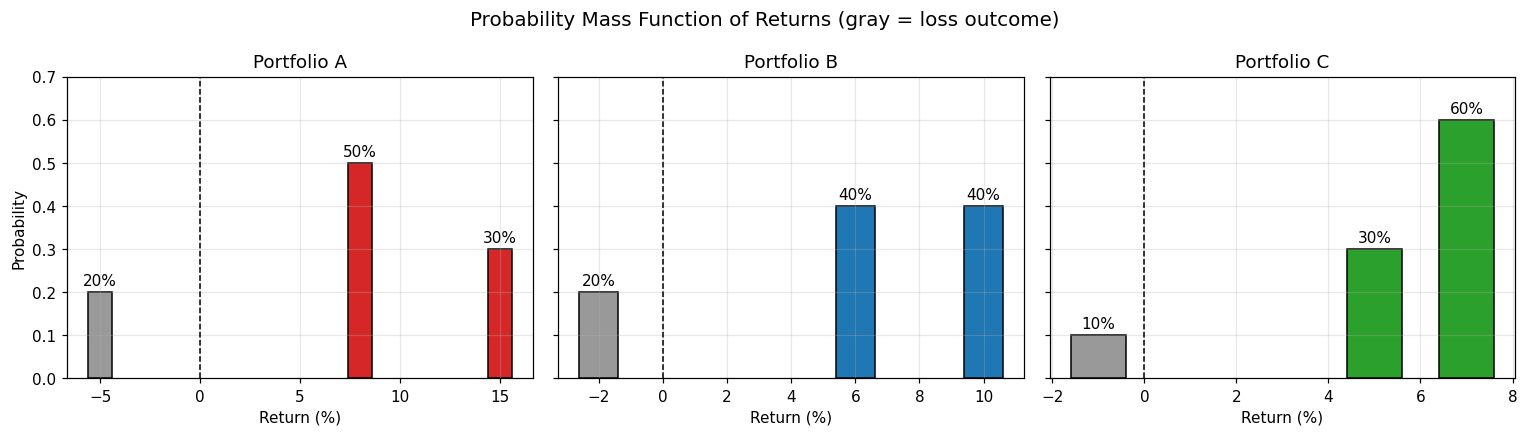

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (name, g) in zip(axes, df.groupby("Portfolio")):
    bar_colors = ["#999999" if r < 0 else COLORS[name] for r in g["Return"]]
    ax.bar(g["Return"] * 100, g["Probability"], width=1.2, color=bar_colors, edgecolor="black")
    for r, p in zip(g["Return"], g["Probability"]):
        ax.text(r * 100, p + 0.015, f"{p:.0%}", ha="center", fontsize=10)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_title(f"Portfolio {name}")
    ax.set_xlabel("Return (%)")
axes[0].set_ylabel("Probability")
axes[0].set_ylim(0, 0.7)
fig.suptitle("Probability Mass Function of Returns (gray = loss outcome)", fontsize=13)
plt.tight_layout()
plt.show()

---
# Part A: Statistical Analysis

For a discrete random variable $R$ with outcomes $r_i$ and probabilities $p_i$:

$$E[R] = \mu = \sum_i r_i \, p_i$$

$$\text{Var}(R) = \sigma^2 = \sum_i (r_i - \mu)^2 \, p_i = E[R^2] - (E[R])^2$$

$$\text{SD}(R) = \sigma = \sqrt{\text{Var}(R)}$$

Variance is computed both ways as a check.

In [5]:
def portfolio_stats(g):
    r = g["Return"].to_numpy()
    p = g["Probability"].to_numpy()
    mu = np.sum(r * p)
    var_def = np.sum((r - mu) ** 2 * p)
    var_short = np.sum(r**2 * p) - mu**2        # shortut var
    sd = np.sqrt(var_def)
    return pd.Series({
        "Expected Return": mu,
        "E[R^2]": np.sum(r**2 * p),
        "Variance (definition)": var_def,
        "Variance (shortcut)": var_short,
        "Std Dev": sd,
    })

theory = df.groupby("Portfolio").apply(portfolio_stats, include_groups=False)
assert np.allclose(theory["Variance (definition)"], theory["Variance (shortcut)"])
theory

,Expected Return,E[R^2],Variance (definition),Variance (shortcut),Std Dev
Portfolio,,,,,
A,0.075000,0.010450,0.004825,0.004825,0.069462
B,0.060000,0.005520,0.001920,0.001920,0.043818
C,0.056000,0.003700,0.000564,0.000564,0.023749


### Step-by-step expected value calculations

In [6]:
for name, g in df.groupby("Portfolio"):
    r, p = g["Return"].to_numpy(), g["Probability"].to_numpy()
    mu = np.sum(r * p)
    terms = " + ".join(f"({ri:+.2f})({pi:.2f})" for ri, pi in zip(r, p))
    var_terms = " + ".join(f"({ri:+.2f} - {mu:.3f})²({pi:.2f})" for ri, pi in zip(r, p))
    var = np.sum((r - mu) ** 2 * p)
    print(f"Portfolio {name}")
    print(f"  E[R]   = {terms} = {mu:.4f}  ({mu:.2%})")
    print(f"  Var(R) = {var_terms}")
    print(f"         = {var:.6f}")
    print(f"  SD(R)  = sqrt({var:.6f}) = {np.sqrt(var):.4f}  ({np.sqrt(var):.2%})\n")

Portfolio A
  E[R]   = (+0.15)(0.30) + (+0.08)(0.50) + (-0.05)(0.20) = 0.0750  (7.50%)
  Var(R) = (+0.15 - 0.075)²(0.30) + (+0.08 - 0.075)²(0.50) + (-0.05 - 0.075)²(0.20)
         = 0.004825
  SD(R)  = sqrt(0.004825) = 0.0695  (6.95%)

Portfolio B
  E[R]   = (+0.10)(0.40) + (+0.06)(0.40) + (-0.02)(0.20) = 0.0600  (6.00%)
  Var(R) = (+0.10 - 0.060)²(0.40) + (+0.06 - 0.060)²(0.40) + (-0.02 - 0.060)²(0.20)
         = 0.001920
  SD(R)  = sqrt(0.001920) = 0.0438  (4.38%)

Portfolio C
  E[R]   = (+0.07)(0.60) + (+0.05)(0.30) + (-0.01)(0.10) = 0.0560  (5.60%)
  Var(R) = (+0.07 - 0.056)²(0.60) + (+0.05 - 0.056)²(0.30) + (-0.01 - 0.056)²(0.10)
         = 0.000564
  SD(R)  = sqrt(0.000564) = 0.0237  (2.37%)



### Summary table

In [7]:
summary_A = pd.DataFrame({
    "Expected Return (%)": theory["Expected Return"] * 100,
    "Variance": theory["Variance (definition)"],
    "Std Dev (%)": theory["Std Dev"] * 100,
    "Coef. of Variation (SD/Mean)": theory["Std Dev"] / theory["Expected Return"],
})
summary_A = summary_A.round({"Expected Return (%)": 2, "Variance": 6, "Std Dev (%)": 2,
                             "Coef. of Variation (SD/Mean)": 3})
summary_A

,Expected Return (%),Variance,Std Dev (%),Coef. of Variation (SD/Mean)
Portfolio,,,,
A,7.500000,0.004825,6.950000,0.926000
B,6.000000,0.001920,4.380000,0.730000
C,5.600000,0.000564,2.370000,0.424000


### Part A interpretation

- **Portfolio A** has the highest expected return (7.5%) but also by far the highest risk: variance 0.004825, standard deviation ≈ 6.95%. Its spread is nearly as large as its average return.
- **Portfolio B** sits in the middle: expected return 6.0%, SD ≈ 4.38% (variance 0.00192).
- **Portfolio C** has the lowest expected return (5.6%) but is way more stable: SD ≈ 2.37% (variance 0.000564), which is about one third of A's SD and about one ninth of A's variance.

Going from C to A gives only 1.9 percentage points of extra expected return, but nearly triples the standard deviation. The coefficient of variation makes this clear since C ≈ 0.42, B ≈ 0.73, A ≈ 0.93.

---
# Part B: Monte Carlo Simulation

Each portfolio's return follows a categorical distribution: three outcomes with fixed probabilities. Drawing 10000 independent returns is equivalent to running the portfolio for 10000 independent periods. By the Law of large numbers, the simulated mean, variance, and loss frequency should converge to their
theoretical values.

In [8]:
N_SIM = 10_000

sims = {}
for name, g in df.groupby("Portfolio"):
    sims[name] = rng.choice(g["Return"].to_numpy(), size=N_SIM, p=g["Probability"].to_numpy())

sim_df = pd.DataFrame(sims)
print(f"Simulated {N_SIM:,} returns per portfolio (seed = {SEED})\n")
sim_df.head(10)

Simulated 10,000 returns per portfolio (seed = 605)



,A,B,C
0,0.150000,0.060000,-0.010000
1,-0.050000,-0.020000,0.070000
2,0.080000,-0.020000,0.070000
3,0.080000,-0.020000,0.070000
4,0.080000,0.060000,0.070000
5,0.150000,0.100000,0.050000
6,0.080000,0.100000,0.070000
7,0.080000,0.100000,0.050000
8,0.080000,-0.020000,0.070000
9,0.150000,0.100000,0.050000


### Simulated vs. theoretical statistics

In [9]:
rows = []
for name in sim_df.columns:
    s = sim_df[name]
    rows.append({
        "Portfolio": name,
        "Theoretical Mean": theory.loc[name, "Expected Return"],
        "Simulated Mean": s.mean(),
        "Theoretical Var": theory.loc[name, "Variance (definition)"],
        "Simulated Var": s.var(ddof=1),
        "Theoretical SD": theory.loc[name, "Std Dev"],
        "Simulated SD": s.std(ddof=1),
    })
compare = pd.DataFrame(rows).set_index("Portfolio")
compare["Mean Error"] = compare["Simulated Mean"] - compare["Theoretical Mean"]
compare["SD % Error"] = (compare["Simulated SD"] / compare["Theoretical SD"] - 1) * 100
compare

,Theoretical Mean,Simulated Mean,Theoretical Var,Simulated Var,Theoretical SD,Simulated SD,Mean Error,SD % Error
Portfolio,,,,,,,,
A,0.075000,0.075028,0.004825,0.004828,0.069462,0.069482,0.000028,0.028203
B,0.060000,0.060460,0.001920,0.001908,0.043818,0.043677,0.000460,-0.321894
C,0.056000,0.055916,0.000564,0.000560,0.023749,0.023665,-0.000084,-0.353733


### Is the gap between simulation and theory just random noise?

The standard error of a simulated mean is $\sigma/\sqrt{N}$. A 95% confidence interval for each simulated mean
should contain the true expected return. A one sample t-test checks the same thing formally.

In [10]:
ci_rows = []
for name in sim_df.columns:
    s = sim_df[name]
    se = s.std(ddof=1) / np.sqrt(N_SIM)
    lo, hi = s.mean() - 1.96 * se, s.mean() + 1.96 * se
    mu_true = theory.loc[name, "Expected Return"]
    t_stat, p_val = stats.ttest_1samp(s, popmean=mu_true)
    ci_rows.append({
        "Portfolio": name,
        "True Mean": mu_true,
        "Sim Mean": s.mean(),
        "Std Error": se,
        "95% CI Low": lo,
        "95% CI High": hi,
        "True Mean in CI?": lo <= mu_true <= hi,
        "t-test p-value": p_val,
    })
pd.DataFrame(ci_rows).set_index("Portfolio")

,True Mean,Sim Mean,Std Error,95% CI Low,95% CI High,True Mean in CI?,t-test p-value
Portfolio,,,,,,,
A,0.075000,0.075028,0.000695,0.073666,0.076390,True,0.967856
B,0.060000,0.060460,0.000437,0.059604,0.061316,True,0.292279
C,0.056000,0.055916,0.000237,0.055452,0.056380,True,0.722627


### Outcome frequencies: simulated vs. expected

In [11]:
freq_rows = []
for name, g in df.groupby("Portfolio"):
    observed = sim_df[name].value_counts().reindex(g["Return"].to_numpy(), fill_value=0)
    expected = g["Probability"].to_numpy() * N_SIM
    chi2, p_val = stats.chisquare(observed.to_numpy(), f_exp=expected)
    for r, o, e in zip(g["Return"], observed, expected):
        freq_rows.append({"Portfolio": name, "Return": r, "Expected Count": e,
                          "Simulated Count": o, "Simulated Prop": o / N_SIM})
    print(f"Portfolio {name}: chi-square goodness of fit = {chi2:.3f}, p-value = {p_val:.3f}")
pd.DataFrame(freq_rows).set_index(["Portfolio", "Return"])

Portfolio A: chi-square goodness of fit = 0.009, p-value = 0.996
Portfolio B: chi-square goodness of fit = 1.252, p-value = 0.535
Portfolio C: chi-square goodness of fit = 2.344, p-value = 0.310


Expected Count  Simulated Count  Simulated Prop
Portfolio Return                                                    
A         0.150000     3,000.000000             3004        0.300400
          0.080000     5,000.000000             4996        0.499600
          -0.050000    2,000.000000             2000        0.200000
B         0.100000     4,000.000000             4051        0.405100
          0.060000     4,000.000000             3981        0.398100
          -0.020000    2,000.000000             1968        0.196800
C         0.070000     6,000.000000             5937        0.593700
          0.050000     3,000.000000             3070        0.307000
          -0.010000    1,000.000000              993        0.099300

### Comparing the simulated return distributions

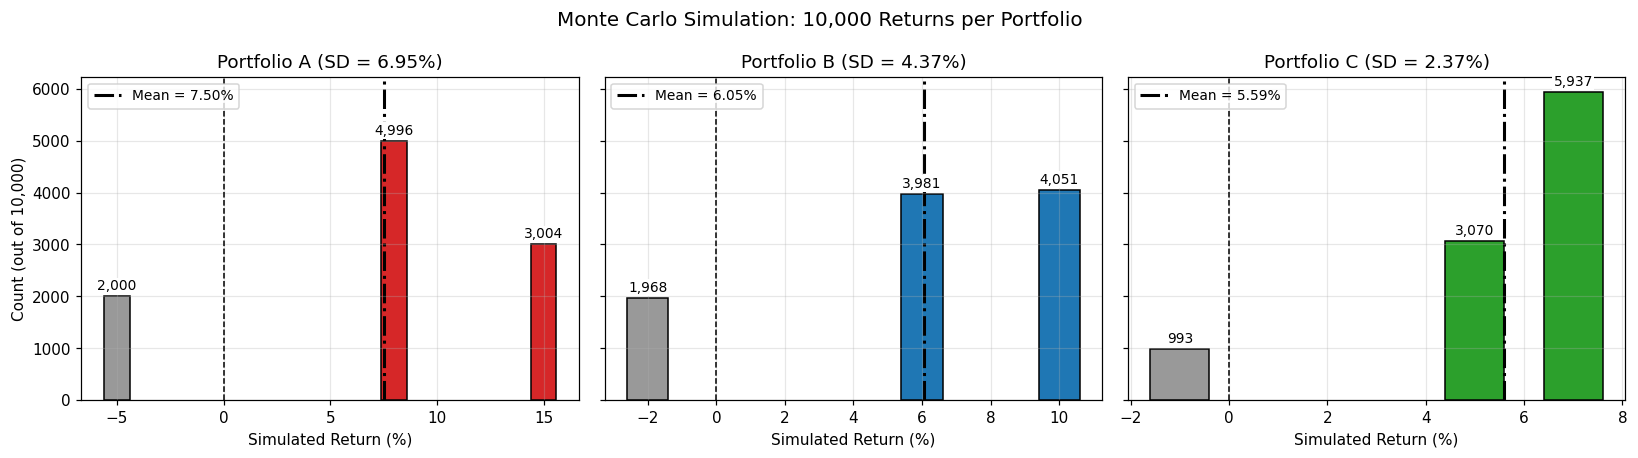

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, name in zip(axes, sim_df.columns):
    s = sim_df[name]
    vals, counts = np.unique(s, return_counts=True)
    bar_colors = ["#999999" if v < 0 else COLORS[name] for v in vals]
    ax.bar(vals * 100, counts, width=1.2, color=bar_colors, edgecolor="black")
    for v, c in zip(vals, counts):
        ax.text(v * 100, c + 120, f"{c:,}", ha="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1), zorder=5)
    ax.axvline(s.mean() * 100, color="black", lw=2, ls="-.", zorder=1, label=f"Mean = {s.mean():.2%}")
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set_title(f"Portfolio {name} (SD = {s.std(ddof=1):.2%})")
    ax.set_xlabel("Simulated Return (%)")
    ax.legend(loc="upper left", fontsize=9)
axes[0].set_ylabel("Count (out of 10,000)")
fig.suptitle("Monte Carlo Simulation: 10,000 Returns per Portfolio", fontsize=13)
plt.tight_layout()
plt.show()

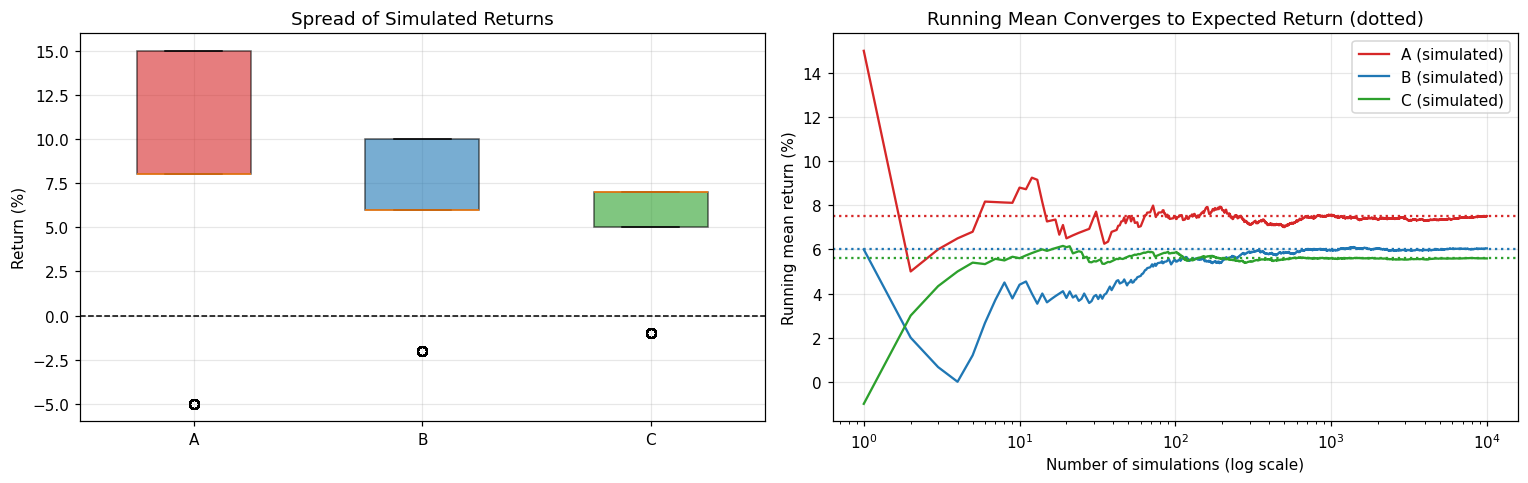

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# box plot witht spread and downside on the same scale
bp = axes[0].boxplot([sim_df[n] * 100 for n in sim_df.columns], patch_artist=True, widths=0.5)
axes[0].set_xticks([1, 2, 3], list(sim_df.columns))
for patch, n in zip(bp["boxes"], sim_df.columns):
    patch.set_facecolor(COLORS[n]); patch.set_alpha(0.6)
axes[0].axhline(0, color="black", ls="--", lw=1)
axes[0].set_title("Spread of Simulated Returns")
axes[0].set_ylabel("Return (%)")

# convergence to see law of large numbers
n_idx = np.arange(1, N_SIM + 1)
for n in sim_df.columns:
    running = sim_df[n].cumsum() / n_idx
    axes[1].plot(n_idx, running * 100, color=COLORS[n], label=f"{n} (simulated)")
    axes[1].axhline(theory.loc[n, "Expected Return"] * 100, color=COLORS[n], ls=":", lw=1.5)
axes[1].set_xscale("log")
axes[1].set_title("Running Mean Converges to Expected Return (dotted)")
axes[1].set_xlabel("Number of simulations (log scale)")
axes[1].set_ylabel("Running mean return (%)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Estimating the probability of a loss

A loss is any return below 0. The simulated estimate is the share of the 10000 draws that were negative. Since each draw is a Bernoulli trial (loss or no loss), the count of losses follows a Binomial(10000, p) distribution, which gives a standard error of $\sqrt{\hat{p}(1-\hat{p})/N}$ for the estimate.

In [14]:
loss_rows = []
for name, g in df.groupby("Portfolio"):
    s = sim_df[name]
    p_true = g.loc[g["Return"] < 0, "Probability"].sum()
    p_hat = (s < 0).mean()
    se = np.sqrt(p_hat * (1 - p_hat) / N_SIM)
    loss_rows.append({
        "Portfolio": name,
        "Exact P(Loss)": p_true,
        "Simulated P(Loss)": p_hat,
        "Losses (count)": int((s < 0).sum()),
        "95% CI Low": p_hat - 1.96 * se,
        "95% CI High": p_hat + 1.96 * se,
        "Expected losing periods per 10": p_true * 10,
    })
loss_df = pd.DataFrame(loss_rows).set_index("Portfolio")
loss_df

,Exact P(Loss),Simulated P(Loss),Losses (count),95% CI Low,95% CI High,Expected losing periods per 10
Portfolio,,,,,,
A,0.200000,0.200000,2000,0.192160,0.207840,2.000000
B,0.200000,0.196800,1968,0.189007,0.204593,2.000000
C,0.100000,0.099300,993,0.093438,0.105162,1.000000


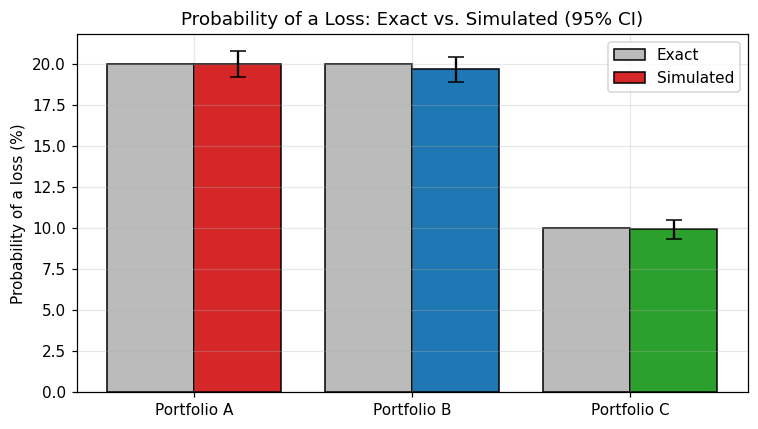

In [15]:
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(loss_df))
ax.bar(x - 0.2, loss_df["Exact P(Loss)"] * 100, 0.4, label="Exact", color="#bbbbbb", edgecolor="black")
ax.bar(x + 0.2, loss_df["Simulated P(Loss)"] * 100, 0.4,
       color=[COLORS[n] for n in loss_df.index], edgecolor="black", label="Simulated")
err = (loss_df["95% CI High"] - loss_df["Simulated P(Loss)"]) * 100
ax.errorbar(x + 0.2, loss_df["Simulated P(Loss)"] * 100, yerr=err, fmt="none", color="black", capsize=5)
ax.set_xticks(x, [f"Portfolio {n}" for n in loss_df.index])
ax.set_ylabel("Probability of a loss (%)")
ax.set_title("Probability of a Loss: Exact vs. Simulated (95% CI)")
ax.legend()
plt.tight_layout()
plt.show()

### Part B interpretation

- **The simulation agrees with the theory.** Every simulated mean is within a fraction of a percentage point of
  its expected value, each true mean falls inside its 95% confidence interval, and the chi-square tests show the
  simulated outcome frequencies are consistent with the stated probabilities. The running-mean plot shows all three
  converging to their expected returns as the number of draws grows (Law of large numbers).
- **Distributions:** A's returns are spread across a 20-point range (-5% to +15%); B's across 12 points (-2% to
  +10%); C's across just 8 points (-1% to +7%). The box plot shows C's entire distribution sits tightly above zero
  except for its small -1% tail.
- **Probability of a loss:** about 20% for A, 20% for B, and 10% for (simulated values within sampling error of the exact 0.20, 0.20, 0.10). A and B lose money in roughly 1 of every 5 periods; C loses in roughly 1 of every 10.

---
# Risk Analysis

Variance treats upside and downside surprises the same, but a risk-sensitive client cares mostly about the downside. The measures below focus on how often, how badly, and how efficiently each portfolio takes risk:

| Measure | What it answers |
|---|---|
| **P(Loss)** | How often do I lose money? |
| **Worst case** | What's the worst single-period outcome? |
| **5% Value at Risk (VaR)** | The return I'd beat 95% of the time |
| **Expected loss given a loss** | When I lose, how much on average? |
| **Downside deviation** | Volatility of returns below 0 only |
| **Return / SD ratio** | Expected return per unit of total risk (Sharpe-style, risk-free rate = 0) |
| **Sortino-style ratio** | Expected return per unit of downside risk |

In [16]:
risk_rows = []
for name, g in df.groupby("Portfolio"):
    r, p = g["Return"].to_numpy(), g["Probability"].to_numpy()
    s = sim_df[name].to_numpy()
    mu = theory.loc[name, "Expected Return"]
    sd = theory.loc[name, "Std Dev"]
    p_loss = p[r < 0].sum()
    exp_loss_given_loss = np.sum(r[r < 0] * p[r < 0]) / p_loss
    downside_dev = np.sqrt(np.sum(np.minimum(r, 0) ** 2 * p))
    risk_rows.append({
        "Portfolio": name,
        "Expected Return": mu,
        "Std Dev": sd,
        "P(Loss)": p_loss,
        "Worst Case": r.min(),
        "Best Case": r.max(),
        "5% VaR (sim)": np.percentile(s, 5),
        "E[R | Loss]": exp_loss_given_loss,
        "Expected Loss Contribution": np.sum(r[r < 0] * p[r < 0]),
        "Downside Dev": downside_dev,
        "Return/SD": mu / sd,
        "Return/Downside Dev": mu / downside_dev,
    })
risk_df = pd.DataFrame(risk_rows).set_index("Portfolio")
risk_df

,Expected Return,Std Dev,P(Loss),Worst Case,Best Case,5% VaR (sim),E[R | Loss],Expected Loss Contribution,Downside Dev,Return/SD,Return/Downside Dev
Portfolio,,,,,,,,,,,
A,0.075000,0.069462,0.200000,-0.050000,0.150000,-0.050000,-0.050000,-0.010000,0.022361,1.079724,3.354102
B,0.060000,0.043818,0.200000,-0.020000,0.100000,-0.020000,-0.020000,-0.004000,0.008944,1.369306,6.708204
C,0.056000,0.023749,0.100000,-0.010000,0.070000,-0.010000,-0.010000,-0.001000,0.003162,2.358025,17.708755


### Ranking each portfolio on every risk measure (1 is best for a risk-averse client)

In [17]:
higher_is_better = ["Expected Return", "Worst Case", "5% VaR (sim)", "E[R | Loss]",
                    "Expected Loss Contribution", "Return/SD", "Return/Downside Dev"]
lower_is_better = ["Std Dev", "P(Loss)", "Downside Dev"]

ranks = pd.concat([
    risk_df[higher_is_better].rank(ascending=False, method="min"),
    risk_df[lower_is_better].rank(ascending=True, method="min"),
], axis=1).astype(int)
ranks = ranks[[c for c in risk_df.columns if c in ranks.columns]]
ranks.T

Portfolio,A,B,C
Expected Return,1,2,3
Std Dev,3,2,1
P(Loss),2,2,1
Worst Case,3,2,1
5% VaR (sim),3,2,1
E[R | Loss],3,2,1
Expected Loss Contribution,3,2,1
Downside Dev,3,2,1
Return/SD,3,2,1
Return/Downside Dev,3,2,1


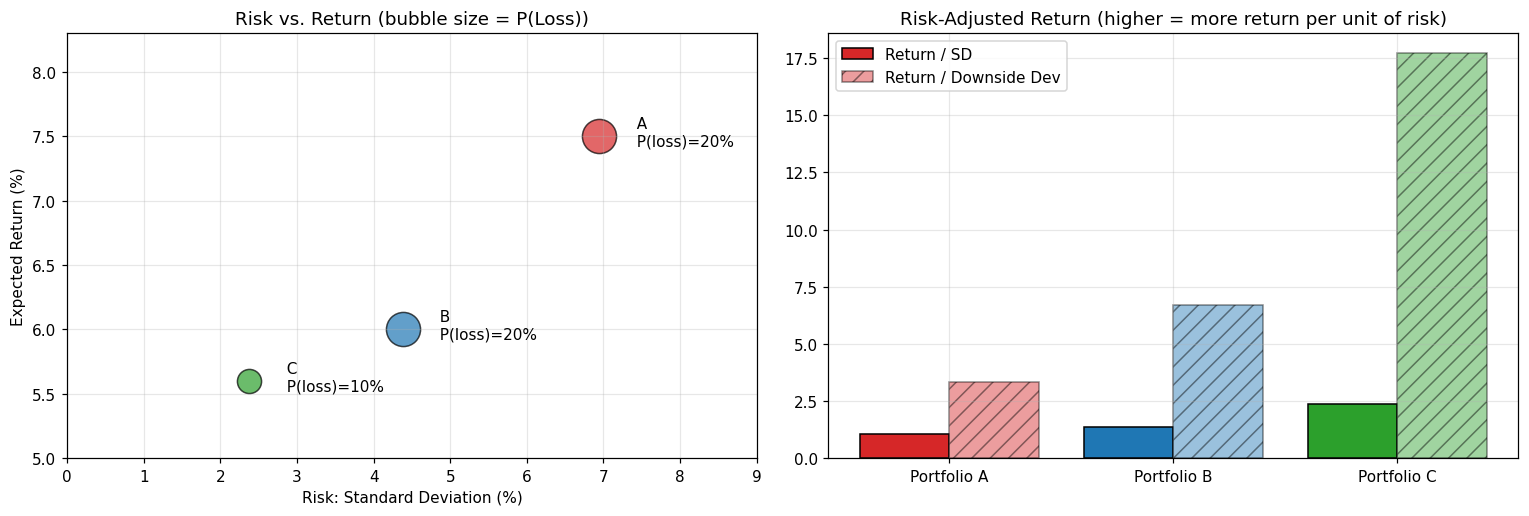

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for n in risk_df.index:
    axes[0].scatter(risk_df.loc[n, "Std Dev"] * 100, risk_df.loc[n, "Expected Return"] * 100,
                    s=2500 * risk_df.loc[n, "P(Loss)"], color=COLORS[n], alpha=0.7, edgecolor="black")
    axes[0].annotate(f"  {n}\n  P(loss)={risk_df.loc[n, 'P(Loss)']:.0%}",
                     (risk_df.loc[n, "Std Dev"] * 100, risk_df.loc[n, "Expected Return"] * 100),
                     xytext=(18, -6), textcoords="offset points", fontsize=10)
axes[0].set_xlabel("Risk: Standard Deviation (%)")
axes[0].set_ylabel("Expected Return (%)")
axes[0].set_title("Risk vs. Return (bubble size = P(Loss))")
axes[0].set_xlim(0, 9); axes[0].set_ylim(5, 8.3)

x = np.arange(len(risk_df))
axes[1].bar(x - 0.2, risk_df["Return/SD"], 0.4, label="Return / SD",
            color=[COLORS[n] for n in risk_df.index], edgecolor="black")
axes[1].bar(x + 0.2, risk_df["Return/Downside Dev"], 0.4, label="Return / Downside Dev",
            color=[COLORS[n] for n in risk_df.index], alpha=0.45, edgecolor="black", hatch="//")
axes[1].set_xticks(x, [f"Portfolio {n}" for n in risk_df.index])
axes[1].set_title("Risk-Adjusted Return (higher = more return per unit of risk)")
axes[1].legend()
plt.tight_layout()
plt.show()

### Simulated cumulative growth over many periods

A single period hides how losses compound. To see what an investor actually experiences over time, I simulate 5000 independent 10-period paths per portfolio and track how \$1 grows. The 5th percentile shows a "bad luck" outcome, and the count of losing periods shows how often an investor would sit through repeated losses.

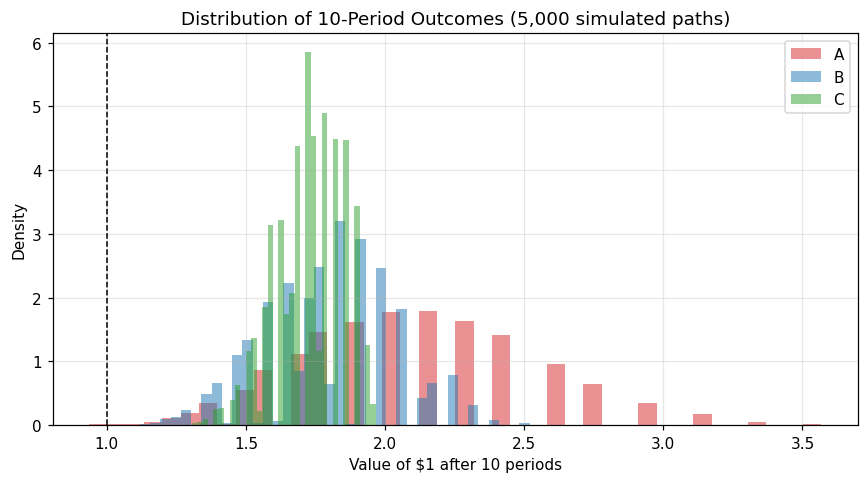

,Median $1 after 10 periods,5th pct $1 after 10 periods,95th pct $1 after 10 periods,P(ending below $1),P(3+ losing periods)
Portfolio,,,,,
A,2.016785,1.461616,2.775453,0.000800,0.317400
B,1.775196,1.409007,2.155226,0.000000,0.307000
C,1.719910,1.500386,1.894300,0.000000,0.068600


In [19]:
N_PATHS, HORIZON = 5_000, 10
path_rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, g in df.groupby("Portfolio"):
    draws = rng.choice(g["Return"].to_numpy(), size=(N_PATHS, HORIZON), p=g["Probability"].to_numpy())
    wealth = np.prod(1 + draws, axis=1)
    losing_periods = (draws < 0).sum(axis=1)
    path_rows.append({
        "Portfolio": name,
        "Median $1 after 10 periods": np.median(wealth),
        "5th pct $1 after 10 periods": np.percentile(wealth, 5),
        "95th pct $1 after 10 periods": np.percentile(wealth, 95),
        "P(ending below $1)": (wealth < 1).mean(),
        "P(3+ losing periods)": (losing_periods >= 3).mean(),
    })
    ax.hist(wealth, bins=40, alpha=0.5, color=COLORS[name], label=name, density=True)
ax.axvline(1, color="black", ls="--", lw=1)
ax.set_xlabel("Value of $1 after 10 periods")
ax.set_ylabel("Density")
ax.set_title("Distribution of 10-Period Outcomes (5,000 simulated paths)")
ax.legend()
plt.tight_layout()
plt.show()

paths_df = pd.DataFrame(path_rows).set_index("Portfolio")
paths_df

### Risk analysis interpretation

- **Portfolio C ranks best on every downside measure.** It has half the loss probability of A and B (10% vs. 20%),the mildest worst case (-1%), and the smallest downside deviation. It also has the best risk-adjusted return by a wide margin: about 2.36 units of return per unit of SD, versus 1.37 for B and 1.08 for A.
- **Portfolio A carries the most risk in every sense.** One period in five it loses 5%, and its total volatility is almost equal to its expected return. It only "wins" on raw expected return and best case.
- **Portfolio B is in an awkward middle.** It loses as often as A (20%), just less severely (-2% vs. -5%). Compared with C, B adds only 0.4 percentage points of expected return while nearly doubling the SD and doubling the loss probability.
- **Note on VaR:** because each portfolio has only three outcomes, the 5% VaR equals the worst case for all three (the loss outcome has at least 10% probability). Expected shortfall and worst case therefore tell the same story.
- **Over 10 periods**, all three portfolios almost always grow (\$1 ends below \$1 in only 0.08% of A's paths and none of B's or C's). A has the highest median (≈ \$2.02 vs. \$1.78 for B and \$1.72 for C), but the widest spread. Most strikingly, C's 5th-percentile outcome (≈ \$1.50) is better than A's (≈ \$1.46) and B's (≈ \$1.41): in a bad-luck scenario, the "safe" portfolio actually ends up ahead.
- **Repeated losses:** A and B suffer 3 or more losing periods out of 10 about 31-32% of the time, versus only ≈ 7% for C. For a risk-sensitive client, sitting through streaks of losses matters as much as the average.

---
# Part C: Investment Recommendation

In [20]:
rec = pd.DataFrame({
    "Expected Return": risk_df["Expected Return"].map("{:.2%}".format),
    "Std Dev": risk_df["Std Dev"].map("{:.2%}".format),
    "P(Loss)": risk_df["P(Loss)"].map("{:.0%}".format),
    "Worst Case": risk_df["Worst Case"].map("{:.0%}".format),
    "Return/SD": risk_df["Return/SD"].round(2),
    "Median $1 → 10 periods": paths_df["Median $1 after 10 periods"].map("${:.3f}".format),
    "Recommended for": ["Aggressive", "Moderate", "Conservative"],
})
rec

,Expected Return,Std Dev,P(Loss),Worst Case,Return/SD,Median $1 → 10 periods,Recommended for
Portfolio,,,,,,,
A,7.50%,6.95%,20%,-5%,1.080000,$2.017,Aggressive
B,6.00%,4.38%,20%,-2%,1.370000,$1.775,Moderate
C,5.60%,2.37%,10%,-1%,2.360000,$1.720,Conservative


### Conservative investors → **Portfolio C**

- Lowest standard deviation (≈ 2.37%) and variance (0.000564), roughly one ninth of A's variance.
- Lowest probability of a loss (10%, confirmed by the simulation at ≈ 9.9%), half that of A or B.
- Mildest worst case: a -1% return. A conservative investor can never lose more than 1% in a single period.
- Best risk-adjusted return (Return/SD ≈ 2.36). The investor gives up only 1.9 points of expected return
  compared with A in exchange for far more stability.
- Best bad-luck outcome over 10 periods (5th percentile ≈ \$1.50 per \$1 invested, vs. \$1.46 for A), and only a ≈ 7% chance of 3+ losing periods out of 10 (vs. ≈ 31% for B and ≈ 32% for A).

This is also the best fit for the firm's risk-sensitive client described in the scenario.

### Moderate investors → **Portfolio B**

- Middle expected return (6.0%) with middle volatility (SD ≈ 4.38%).
- Losses are more frequent (20%) but limited to -2%, so the downside is still small and capped.
- Suits an investor willing to accept occasional small losses for a little more return than C.

**Caveat:** the numbers show B is only a modest step up from C in return (+0.4 points) while doubling both the SD and the loss probability; its Return/SD (≈ 1.37) is well below C's. A moderate investor who is truly focused on risk adjusted return may reasonably prefer C as well. B is recommended here because it best matches a moderate appetite for risk, not because it is the most efficient portfolio.

### Aggressive investors → **Portfolio A**

- Highest expected return (7.5%) and the highest upside (+15% with 30% probability).
- Highest median growth over 10 periods (≈ \$2.02 per \$1 vs. \$1.72 for C), and the best 95th-percentile outcome (≈ \$2.78).
- Highest risk: SD ≈ 6.95%, a 20% chance of a loss, and a worst case of -5%.
- Appropriate only for an investor who can tolerate frequent, larger losses and a wide range of multi-period outcomes in pursuit of the highest average return.

### Summary

| Investor | Portfolio | Key evidence |
|---|---|---|
| Conservative | **C** | Lowest SD (2.37%), lowest P(loss) (10%), worst case -1%, best Return/SD (2.36) |
| Moderate | **B** | Middle return (6.0%) and risk (SD 4.38%), losses capped at -2% |
| Aggressive | **A** | Highest return (7.5%) and upside (+15%), accepts SD 6.95% and −5% losses |

### Limitations

- Each portfolio is modeled with only three discrete outcomes; real returns are continuous and can include rare extreme losses not captured here.
- Periods are assumed independent, and the probabilities are assumed known and stable over time.
